# Food Delivery Sales Analysis — Customer & Sales Focus
**Course:** Data Analytics with Python  
**Project type:** Group assignment  
**Dataset:** 600 synthetic food-delivery order records (`food_delivery_orders.csv`)

## Executive summary
This project uses Python to analyze food-delivery sales and customer behaviour. It measures delivered revenue, average order value, monthly sales, city performance, customer segments, repeat purchases, cuisine preferences, discounts, ratings, and order status. The notebook is written as a reproducible analysis: run the cells from top to bottom and use the displayed results in the final report.

> **Data integrity note:** The supplied CSV is synthetic classroom data, not records from a real company. All conclusions apply only to this sample. Revenue is not profit because food costs, restaurant commissions, delivery costs, and marketing costs are not included.


## 1. Problem statement
Food-delivery businesses need to understand which customers contribute most to sales, which locations and cuisines perform well, and whether customers return to place additional orders. Looking only at total sales can hide important patterns: revenue may come from many customers with small orders or from a small group of high-spending customers.

This project analyzes order-level data to answer:
- How much revenue came from delivered orders?
- What is the average order value (AOV)?
- Which months and cities generated the most sales?
- Which customer segments and cuisines contributed most to revenue?
- How many customers placed repeat orders?
- What do discounts, ratings, cancellations, and refunds suggest about customer experience?


## 2. Objectives
1. Load, inspect, and prepare the dataset using Pandas.
2. Check missing values and duplicate order IDs.
3. Calculate key sales KPIs: order count, delivered revenue, AOV, unique customers, repeat customers, cancellation rate, and refund rate.
4. Compare monthly and city-wise sales.
5. Compare customer segments, cuisines, ordering channels, and payment methods.
6. Identify high-spending customers and repeat-purchase frequency.
7. Visualize results with Matplotlib.
8. Convert the analysis into practical, evidence-based recommendations.


## 3. Tools and libraries
- **Python:** general-purpose programming language.
- **Pandas:** reads CSV files, cleans columns, groups transactions, and calculates summaries.
- **NumPy:** supports numerical calculations and missing-value checks.
- **Matplotlib:** creates line charts, bar charts, and histograms.
- **Jupyter Notebook:** combines explanations, code, tables, and charts in one report.

Install the libraries if needed: `pip install pandas numpy matplotlib jupyter`.


## 4. Dataset description

The CSV contains one row per order and the following important fields:

| Column | Meaning |
|---|---|
| `order_id` | Unique order identifier |
| `order_date` | Date of order |
| `customer_id` | Customer identifier |
| `city` | Customer/order city |
| `customer_segment` | New, Regular, or Premium |
| `order_channel` | App, Website, or Phone |
| `cuisine` | Cuisine category |
| `quantity` | Number of items |
| `unit_price_inr` | Unit price in rupees |
| `discount_pct` | Discount rate as a decimal |
| `discount_amount_inr` | Discount amount in rupees |
| `delivery_fee_inr` | Delivery fee in rupees |
| `total_amount_inr` | Final order amount after discount plus delivery fee |
| `payment_method` | Payment method used |
| `rating` | Customer rating from 1 to 5 |
| `order_status` | Delivered, Cancelled, or Refunded |

**Important metric rule:** only `Delivered` orders are used to calculate sales revenue and AOV. All order statuses are included when calculating cancellation and refund rates.


## 5. Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("food_delivery_orders.csv", parse_dates=["order_date"])

print("Dataset shape:", df.shape)
print("\\nFirst 5 rows:")
display(df.head())
print("\\nColumn data types:")
display(df.dtypes.to_frame("data_type"))


Dataset shape: (600, 16)
\nFirst 5 rows:


,order_id,order_date,customer_id,city,customer_segment,order_channel,cuisine,quantity,unit_price_inr,discount_pct,discount_amount_inr,delivery_fee_inr,total_amount_inr,payment_method,rating,order_status
0,O10001,2025-02-02,C0111,Hubballi,Regular,Website,Italian,5,120,0.05,30.0,40,610.0,Debit Card,1,Delivered
1,O10002,2025-10-10,C0141,Mysuru,Regular,App,Indian,3,250,0.05,37.5,40,752.5,UPI,4,Delivered
2,O10003,2025-08-27,C0134,Mangaluru,Regular,App,South Indian,5,250,0.15,187.5,20,1082.5,UPI,4,Delivered
3,O10004,2025-06-10,C0025,Hubballi,Premium,Phone,South Indian,4,180,0.10,72.0,40,688.0,Cash,4,Delivered
4,O10005,2025-06-08,C0149,Hubballi,Regular,App,South Indian,4,150,0.00,0.0,40,640.0,Cash,3,Delivered


\nColumn data types:


,data_type
order_id,object
order_date,datetime64[ns]
customer_id,object
city,object
customer_segment,object
order_channel,object
cuisine,object
quantity,int64
unit_price_inr,int64
discount_pct,float64


### Expected output
- Dataset shape should be **(600, 16)** for the supplied sample dataset.
- The first five records should display in a table.
- `order_date` should have a datetime data type; most other columns should be numeric or text.
- Exact row values depend on the CSV file you use. If you replace the sample with your own dataset, update the expected shape accordingly.


## 6. Data quality checks and preparation

In [2]:
print("Missing values per column:")
display(df.isna().sum().to_frame("missing_values"))

print("Duplicate order IDs:", df["order_id"].duplicated().sum())

# Remove duplicate order IDs if any exist.
df = df.drop_duplicates(subset="order_id").copy()

# Remove accidental spaces and standardize text fields.
text_cols = ["city", "customer_segment", "order_channel", "cuisine",
             "payment_method", "order_status"]
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()

# Create a month field for time-based analysis.
df["month"] = df["order_date"].dt.to_period("M").astype(str)
df["is_delivered"] = df["order_status"].eq("Delivered")

delivered = df.loc[df["is_delivered"]].copy()

print("Rows after duplicate handling:", len(df))
print("Delivered orders:", len(delivered))
print("Month range:", df["order_date"].min().date(), "to", df["order_date"].max().date())


Missing values per column:


,missing_values
order_id,0
order_date,0
customer_id,0
city,0
customer_segment,0
order_channel,0
cuisine,0
quantity,0
unit_price_inr,0
discount_pct,0


Duplicate order IDs: 0
Rows after duplicate handling: 600
Delivered orders: 551
Month range: 2025-01-02 to 2025-12-31


### Explanation
Missing-value counts show whether any column needs attention. Duplicate order IDs are checked because duplicate transactions could inflate sales. Text fields are trimmed to avoid categories such as `"App"` and `"App "` being treated as different values. The `month` field makes monthly grouping easier. Finally, a separate `delivered` DataFrame is created for sales analysis.

### Expected output
- The missing-value table should show the count for every column.
- Duplicate order IDs should be `0` for the supplied dataset.
- Rows after duplicate handling should be `600`.
- Delivered orders should be fewer than or equal to 600.
- The date range should fall within 2025 for the supplied sample.


## 7. Key sales performance indicators (KPIs)

In [3]:
delivered_revenue = delivered["total_amount_inr"].sum()
delivered_orders = len(delivered)
aov = delivered_revenue / delivered_orders if delivered_orders else 0

unique_customers = delivered["customer_id"].nunique()
orders_per_customer = delivered.groupby("customer_id")["order_id"].nunique()
repeat_customers = int((orders_per_customer >= 2).sum())

cancel_rate = df["order_status"].eq("Cancelled").mean() * 100
refund_rate = df["order_status"].eq("Refunded").mean() * 100

kpis = pd.DataFrame({
    "Metric": [
        "Total orders", "Delivered orders", "Delivered revenue (INR)",
        "Average order value (INR)", "Unique customers with delivered orders",
        "Repeat customers (2+ delivered orders)", "Cancellation rate (%)",
        "Refund rate (%)"
    ],
    "Value": [
        len(df), delivered_orders, round(delivered_revenue, 2), round(aov, 2),
        unique_customers, repeat_customers, round(cancel_rate, 2), round(refund_rate, 2)
    ]
})
display(kpis)


,Metric,Value
0,Total orders,600.00
1,Delivered orders,551.00
2,Delivered revenue (INR),425294.00
3,Average order value (INR),771.86
4,Unique customers with delivered orders,174.00
5,Repeat customers (2+ delivered orders),147.00
6,Cancellation rate (%),6.17
7,Refund rate (%),2.00


### Explanation
- **Delivered revenue** is the sum of final order amounts for delivered orders.
- **AOV** = delivered revenue ÷ delivered order count.
- **Unique customers** counts customers with at least one delivered order.
- **Repeat customers** are customers with two or more delivered orders.
- **Cancellation rate** = cancelled orders ÷ all orders × 100.
- **Refund rate** = refunded orders ÷ all orders × 100.

### Expected output
A table with eight KPI rows. For this dataset, total orders should be 600. The other numeric values are calculated from the CSV at runtime; use the values displayed by your notebook in the report rather than copying estimates.


## 8. Monthly sales trend

,month,revenue_inr,orders,customers
0,2025-01,26768.0,39,31
1,2025-02,49755.0,55,47
2,2025-03,32307.0,41,32
3,2025-04,41440.0,51,42
4,2025-05,24832.5,33,29
5,2025-06,44451.5,56,45
6,2025-07,30810.0,46,38
7,2025-08,31585.0,43,37
8,2025-09,34307.5,41,38
9,2025-10,47101.0,60,51


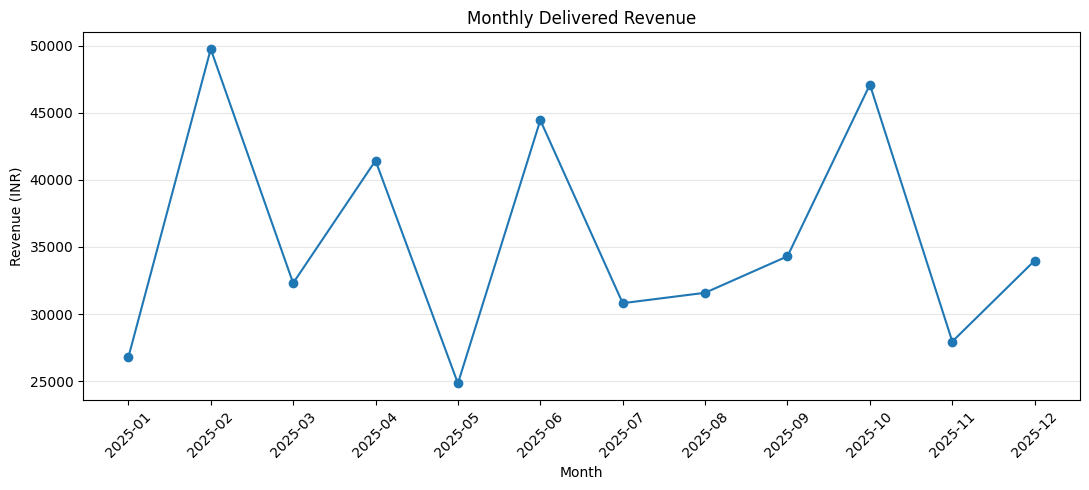

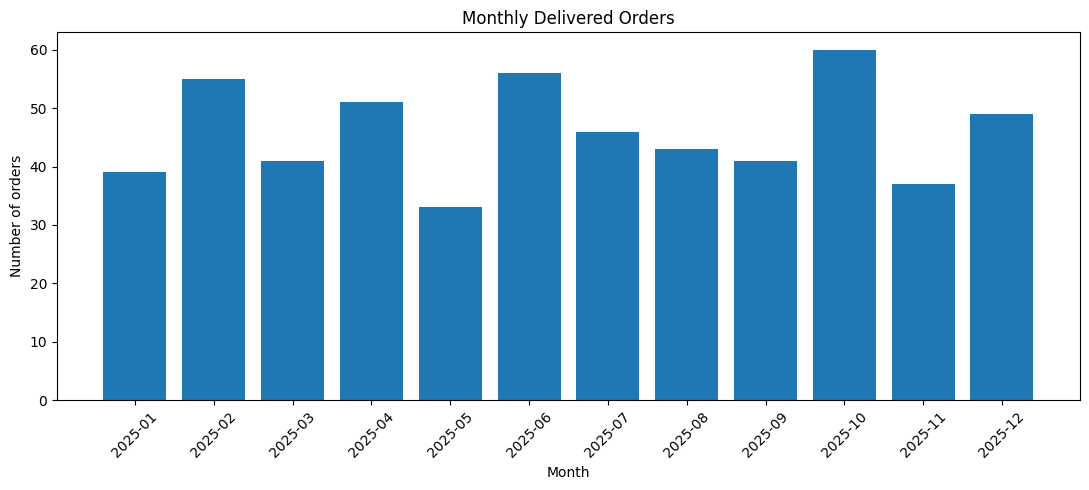

In [4]:
monthly_sales = delivered.groupby("month").agg(
    revenue_inr=("total_amount_inr", "sum"),
    orders=("order_id", "count"),
    customers=("customer_id", "nunique")
).reset_index()

display(monthly_sales.round(2))

plt.figure(figsize=(11, 5))
plt.plot(monthly_sales["month"], monthly_sales["revenue_inr"], marker="o")
plt.title("Monthly Delivered Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
plt.bar(monthly_sales["month"], monthly_sales["orders"])
plt.title("Monthly Delivered Orders")
plt.xlabel("Month")
plt.ylabel("Number of orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Explanation
The monthly summary calculates delivered revenue, delivered order count, and unique customers for each month. The line chart makes changes in revenue easier to see, while the bar chart compares order volume.

### Expected output
- A monthly table with one row for each month that contains delivered orders.
- One line chart for revenue and one bar chart for order count.
- Use the table to identify the highest- and lowest-revenue months. A high-revenue month can result from more orders, higher AOV, or both; check all three before explaining the cause.


## 9. City-wise sales performance

,revenue_inr,orders,aov_inr,customers
city,,,,
Udupi,98892.0,128,772.59,93
Mangaluru,90818.0,119,763.18,85
Hubballi,81170.5,105,773.05,79
Mysuru,80762.0,103,784.10,82
Bengaluru,73651.5,96,767.20,71


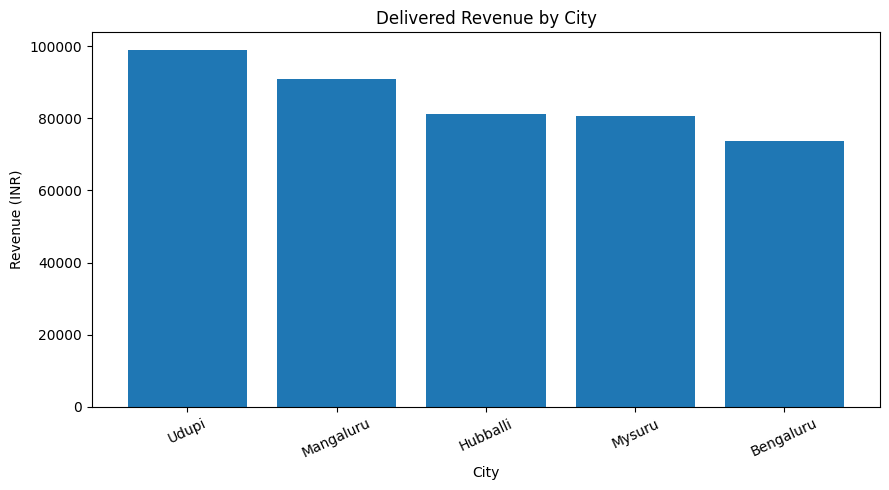

In [5]:
city_sales = delivered.groupby("city").agg(
    revenue_inr=("total_amount_inr", "sum"),
    orders=("order_id", "count"),
    aov_inr=("total_amount_inr", "mean"),
    customers=("customer_id", "nunique")
).sort_values("revenue_inr", ascending=False).round(2)

display(city_sales)

plt.figure(figsize=(9, 5))
plt.bar(city_sales.index, city_sales["revenue_inr"])
plt.title("Delivered Revenue by City")
plt.xlabel("City")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


### Explanation
City analysis compares total delivered revenue with order count, AOV, and customer count. The city with the highest revenue is not automatically the city with the highest AOV or best customer retention.

### Expected output
- A table with one row per city.
- A bar chart showing revenue by city.
- Identify the leading city by revenue from the first row, then compare AOV and customer count to understand the result.


## 10. Customer segment analysis

,revenue_inr,orders,aov_inr,customers
customer_segment,,,,
Regular,223896.0,292,766.77,143
New,130575.5,162,806.02,106
Premium,70822.5,97,730.13,76


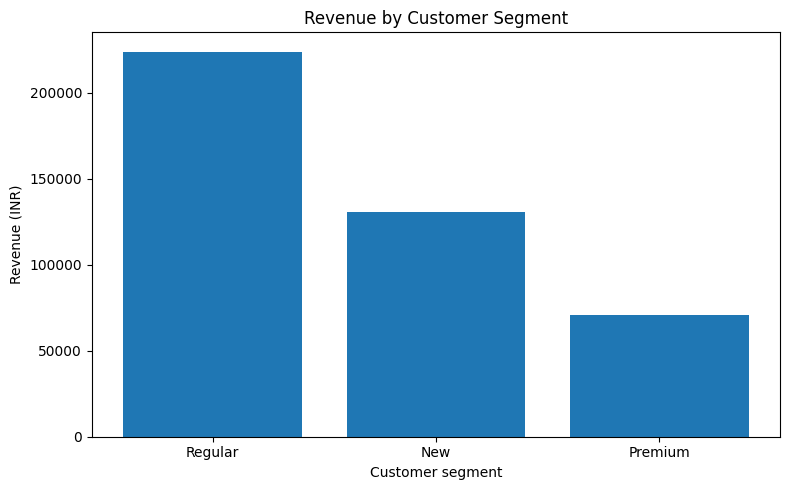

In [6]:
segment_sales = delivered.groupby("customer_segment").agg(
    revenue_inr=("total_amount_inr", "sum"),
    orders=("order_id", "count"),
    aov_inr=("total_amount_inr", "mean"),
    customers=("customer_id", "nunique")
).sort_values("revenue_inr", ascending=False).round(2)

display(segment_sales)

plt.figure(figsize=(8, 5))
plt.bar(segment_sales.index, segment_sales["revenue_inr"])
plt.title("Revenue by Customer Segment")
plt.xlabel("Customer segment")
plt.ylabel("Revenue (INR)")
plt.tight_layout()
plt.show()


### Explanation
The segment comparison shows whether New, Regular, or Premium customers contribute the most revenue. Revenue should be interpreted alongside customer count and AOV. For example, a segment may lead in total revenue because it contains more customers, not because each customer spends more.

### Expected output
- A summary table for each segment.
- A bar chart comparing segment revenue.
- State which segment contributes the most revenue and whether its AOV is also high.


## 11. Top customers and repeat-purchase behaviour

Top 10 customers by total delivered spend:


,delivered_orders,total_spend_inr,average_order_value_inr,last_order_date
customer_id,,,,
C0166,9,10430.0,1158.89,2025-12-18
C0111,9,7195.0,799.44,2025-07-30
C0154,8,7090.0,886.25,2025-12-04
C0133,7,6035.0,862.14,2025-12-09
C0003,6,5989.0,998.17,2025-12-05
C0115,7,5872.5,838.93,2025-11-22
C0045,5,5500.0,1100.00,2025-11-22
C0081,7,5444.0,777.71,2025-11-13
C0079,5,5355.0,1071.00,2025-08-30


Number of customers by delivered-order frequency:


,number_of_customers
delivered_orders,
1,27
2,41
3,47
4,24
5,18
6,9
7,5
8,1
9,2


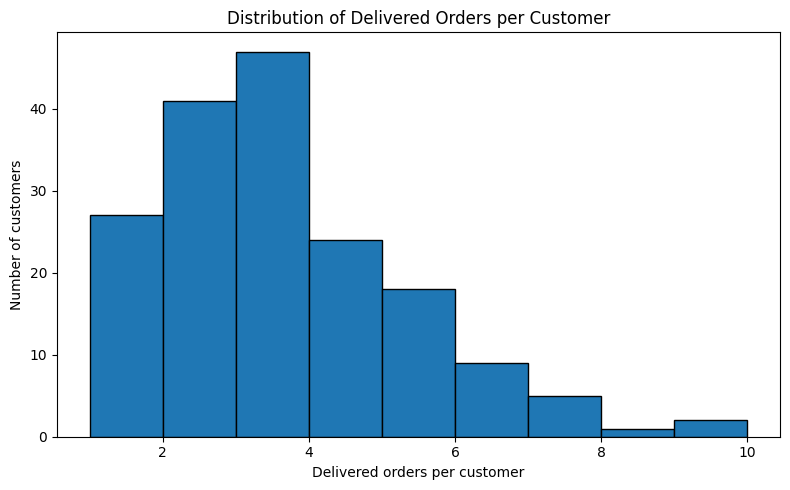

In [7]:
customer_summary = delivered.groupby("customer_id").agg(
    delivered_orders=("order_id", "count"),
    total_spend_inr=("total_amount_inr", "sum"),
    average_order_value_inr=("total_amount_inr", "mean"),
    last_order_date=("order_date", "max")
).sort_values("total_spend_inr", ascending=False)

print("Top 10 customers by total delivered spend:")
display(customer_summary.head(10).round(2))

frequency = customer_summary["delivered_orders"].value_counts().sort_index()
print("Number of customers by delivered-order frequency:")
display(frequency.to_frame("number_of_customers").rename_axis("delivered_orders"))

plt.figure(figsize=(8, 5))
plt.hist(customer_summary["delivered_orders"],
         bins=range(1, int(customer_summary["delivered_orders"].max()) + 2),
         edgecolor="black")
plt.title("Distribution of Delivered Orders per Customer")
plt.xlabel("Delivered orders per customer")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()


### Explanation
Each customer's delivered order count, total spend, average spend per order, and most recent order date are calculated. The top-ten table helps identify high-value customers. The frequency table and histogram show how many customers ordered once, twice, or more often.

### Expected output
- A top-10 customer table sorted by total spend.
- A frequency table with delivered order count as the index.
- A histogram of order frequency.
- Do not publish identifiable personal data; customer IDs here are artificial identifiers.


## 12. Cuisine and ordering channel analysis

In [8]:
cuisine_sales = delivered.groupby("cuisine").agg(
    revenue_inr=("total_amount_inr", "sum"),
    orders=("order_id", "count"),
    aov_inr=("total_amount_inr", "mean")
).sort_values("revenue_inr", ascending=False).round(2)

channel_sales = delivered.groupby("order_channel").agg(
    revenue_inr=("total_amount_inr", "sum"),
    orders=("order_id", "count"),
    aov_inr=("total_amount_inr", "mean")
).sort_values("revenue_inr", ascending=False).round(2)

print("Cuisine performance:")
display(cuisine_sales)
print("Order channel performance:")
display(channel_sales)


Cuisine performance:


,revenue_inr,orders,aov_inr
cuisine,,,
Italian,82524.5,100,825.24
Chinese,80311.5,98,819.51
Fast Food,75340.0,98,768.78
Indian,65978.5,93,709.45
Desserts,61969.0,80,774.61
South Indian,59170.5,82,721.59


Order channel performance:


,revenue_inr,orders,aov_inr
order_channel,,,
App,317663.5,407,780.50
Website,84375.5,117,721.16
Phone,23255.0,27,861.30


### Explanation
Cuisine analysis helps identify categories with high revenue and order volume. Channel analysis compares App, Website, and Phone orders. Because the sample contains different numbers of orders by channel, compare both total revenue and AOV rather than revenue alone.

### Expected output
Two tables: one cuisine summary and one channel summary. Use them to name the top cuisine and top channel by revenue, and check whether their AOVs tell the same story.


## 13. Discounts, ratings, payment methods, and order status

Discount-level comparison:


,orders,revenue_inr,aov_inr
discount_pct,,,
0.00,248,196730.0,793.27
0.05,81,67498.0,833.31
0.10,97,74355.0,766.55
0.15,74,54379.0,734.85
0.20,51,32332.0,633.96


Rating summary:


,orders,revenue_inr
rating,,
1,20,12584.5
2,33,21762.0
3,123,92996.0
4,208,163830.5
5,167,134121.0


Payment method summary:


,orders,revenue_inr
payment_method,,
UPI,143,114396.0
Cash,140,104791.5
Debit Card,143,103977.5
Credit Card,125,102129.0


All-order status counts:


,orders
order_status,
Delivered,551
Cancelled,37
Refunded,12


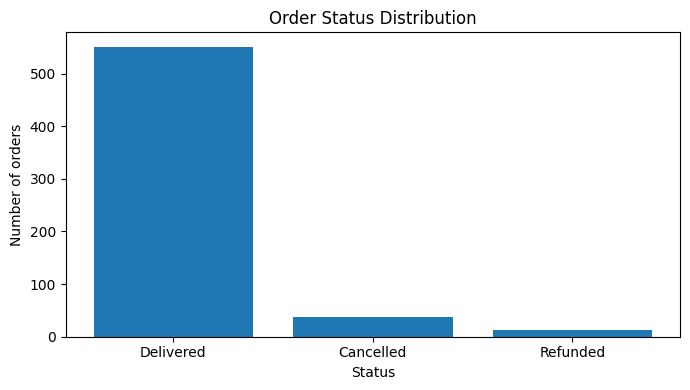

In [9]:
discount_analysis = delivered.groupby("discount_pct").agg(
    orders=("order_id", "count"),
    revenue_inr=("total_amount_inr", "sum"),
    aov_inr=("total_amount_inr", "mean")
).sort_index().round(2)

rating_analysis = delivered.groupby("rating").agg(
    orders=("order_id", "count"),
    revenue_inr=("total_amount_inr", "sum")
).sort_index().round(2)

payment_analysis = delivered.groupby("payment_method").agg(
    orders=("order_id", "count"),
    revenue_inr=("total_amount_inr", "sum")
).sort_values("revenue_inr", ascending=False).round(2)

status_counts = df["order_status"].value_counts().to_frame("orders")

print("Discount-level comparison:")
display(discount_analysis)
print("Rating summary:")
display(rating_analysis)
print("Payment method summary:")
display(payment_analysis)
print("All-order status counts:")
display(status_counts)

plt.figure(figsize=(7, 4))
plt.bar(status_counts.index, status_counts["orders"])
plt.title("Order Status Distribution")
plt.xlabel("Status")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.show()


### Explanation
Discount analysis compares order count, revenue, and AOV at each discount level. Ratings are summarized to inspect customer feedback. Payment-method analysis shows how delivered revenue is distributed. Order status counts include delivered, cancelled, and refunded orders.

### Expected output
- A discount summary table.
- A rating summary table.
- A payment-method table.
- A status-count table and bar chart.
- **Caution:** this dataset does not include profit margins or cancellation reasons. A discount level with high sales cannot automatically be called the most profitable.


## 14. Cross-analysis: customer segment by city

In [10]:
segment_city = pd.pivot_table(
    delivered,
    values="total_amount_inr",
    index="city",
    columns="customer_segment",
    aggfunc="sum",
    fill_value=0
).round(2)

print("Revenue by city and customer segment:")
display(segment_city)

print("Order count by city and segment:")
display(pd.crosstab(delivered["city"], delivered["customer_segment"]))


Revenue by city and customer segment:


customer_segment,New,Premium,Regular
city,,,
Bengaluru,24828.5,12460.0,36363.0
Hubballi,22648.0,14491.5,44031.0
Mangaluru,23612.5,18838.0,48367.5
Mysuru,23999.0,9766.5,46996.5
Udupi,35487.5,15266.5,48138.0


Order count by city and segment:


customer_segment,New,Premium,Regular
city,,,
Bengaluru,33,18,45
Hubballi,29,22,54
Mangaluru,30,21,68
Mysuru,27,17,59
Udupi,43,19,66


### Explanation
A pivot table compares the revenue contributed by each customer segment within each city. The cross-tabulation compares order counts. This helps avoid a one-size-fits-all campaign strategy: different cities may have different customer mixes.

### Expected output
- A revenue pivot table with cities as rows and segments as columns.
- An order-count cross-tabulation.
- Use the table to identify city-segment combinations that may be worth testing with targeted promotions.


## 15. Findings and interpretation

After running the notebook, write 5–8 findings using actual output values. Use this template:

1. **Sales:** Delivered revenue was ₹________ across ________ delivered orders. AOV was ₹________.
2. **Monthly trend:** The highest-revenue month was ________, with ₹________.
3. **City:** ________ had the highest delivered revenue; its AOV was ₹________.
4. **Customer segment:** ________ contributed the highest revenue. It had ________ customers and an AOV of ₹________.
5. **Customer loyalty:** ________ customers placed at least two delivered orders. This was ________% of customers with delivered orders.
6. **Cuisine/channel:** ________ was the top cuisine by revenue, while ________ was the top order channel.
7. **Customer experience:** The cancellation rate was ________% and the refund rate was ________%.
8. **Discounts:** The discount level with the most orders was ________. Check AOV and profit data before claiming it is best.

Do not fill in the blanks by guessing. Copy figures from the notebook output. If your actual dataset differs, your findings will differ too.


## 16. Recommendations

1. **Increase repeat purchases:** Send reorder reminders or targeted offers to customers with only one delivered order.
2. **Reward high-value customers:** Use transparent loyalty tiers based on frequency and spend, while monitoring campaign cost.
3. **Localize marketing:** Set city-specific campaigns based on revenue, AOV, and customer counts.
4. **Test cuisine promotions:** Feature high-performing cuisines and run controlled experiments for lower-performing categories.
5. **Evaluate discounts properly:** Compare order lift and AOV across discount levels; add cost and margin data before judging profitability.
6. **Reduce cancellations and refunds:** Collect cancellation reasons, delivery delays, restaurant preparation time, and payment failures.
7. **Improve customer analytics:** Add signup date and acquisition channel to measure cohorts and retention.
8. **Track profit, not only revenue:** Add food costs, delivery costs, commissions, and promotional costs to estimate contribution margin.


## 17. Limitations

- The data is synthetic and does not describe an actual company.
- One row represents an order, not an individual food item.
- No restaurant-level data or delivery-time data is available.
- Profit cannot be calculated because cost and commission fields are missing.
- Customer lifetime value and cohort retention require longer, reliable customer history.
- Correlation or group differences do not prove that a discount, rating, or channel caused a sales outcome.


## 18. Conclusion

This project demonstrates how Python supports data-driven analysis of food delivery sales and customer behaviour. Pandas prepares and aggregates transactions, NumPy supports numerical processing, and Matplotlib communicates trends visually. The analysis identifies high-revenue periods, cities, customer segments, cuisines, and repeat-order patterns. The most useful next step is to validate these patterns using real business data and add cost, delivery-time, and cancellation-reason fields so that recommendations can be evaluated against profit and customer experience.


## 19. Suggested group task division

| Member | Task | Deliverable |
|---|---|---|
| Member 1 | Dataset, data quality, preprocessing | Dataset description and cleaning explanation |
| Member 2 | KPIs, monthly trend, city sales | KPI table and sales charts |
| Member 3 | Customer segments, top customers, repeat purchases | Customer analysis tables and interpretation |
| Member 4 | Cuisine/channel, discounts, findings, recommendations | Final discussion and presentation |

All group members should review the final outputs and agree on the interpretation before submitting.
